<a href="https://colab.research.google.com/github/raveenask14-cpu/ITA0607---ML/blob/main/IET_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# SMART CAMPUS ENERGY CONSUMPTION PREDICTION
# Instance-Based Learning + Data Analytics
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

# Reproducibility
np.random.seed(42)

print("Libraries imported successfully.")
print("Random seed = 42")

Libraries imported successfully.
Random seed = 42


In [2]:
# ============================================================
# DATASET CREATION
# ============================================================

n = 300

building_ids = np.random.choice(
    ["B01", "B02", "B03", "B04", "B05"],
    n
)

dates = pd.date_range(
    start="2026-01-01",
    periods=n,
    freq="6h"
)

occupancy = np.random.randint(10, 101, n)

temperature = np.round(
    np.random.normal(29, 4, n), 1
)

humidity = np.round(
    np.random.normal(65, 10, n), 1
)

ac_hours = np.round(
    np.clip(
        3 + 0.20 * (temperature - 24)
        + np.random.normal(0, 1.2, n),
        0, 12
    ), 1
)

lighting_hours = np.round(
    np.clip(
        2 + occupancy / 15
        + np.random.normal(0, 1, n),
        1, 12
    ), 1
)

equipment_load = np.round(
    np.clip(
        5 + occupancy * 0.25
        + np.random.normal(0, 3, n),
        2, 35
    ), 1
)

renewable_energy = np.round(
    np.random.uniform(0, 10, n), 2
)

# Energy consumption model used only to create realistic synthetic data
total_energy = (
    10
    + 0.20 * occupancy
    + 1.8 * ac_hours
    + 1.2 * lighting_hours
    + 1.4 * equipment_load
    + 0.35 * temperature
    - 0.7 * renewable_energy
    + np.random.normal(0, 5, n)
)

total_energy = np.round(
    np.maximum(total_energy, 5), 2
)

df = pd.DataFrame({
    "Building_ID": building_ids,
    "Date_Time": dates,
    "Occupancy": occupancy,
    "Temperature": temperature,
    "Humidity": humidity,
    "AC_Hours": ac_hours,
    "Lighting_Hours": lighting_hours,
    "Equipment_Load": equipment_load,
    "Renewable_Energy_kWh": renewable_energy,
    "Total_Energy_kWh": total_energy
})

print("Dataset created successfully.")
print("Number of records:", len(df))
print("Number of columns:", len(df.columns))

display(df.head())

Dataset created successfully.
Number of records: 300
Number of columns: 10


,Building_ID,Date_Time,Occupancy,Temperature,Humidity,AC_Hours,Lighting_Hours,Equipment_Load,Renewable_Energy_kWh,Total_Energy_kWh
0,B04,2026-01-01 00:00:00,46,18.7,56.3,1.7,5.6,19.2,5.26,62.02
1,B05,2026-01-01 06:00:00,33,33.6,48.9,3.5,5.2,17.5,5.12,60.44
2,B03,2026-01-01 12:00:00,55,21.4,78.5,2.0,5.9,19.0,1.66,69.18
3,B05,2026-01-01 18:00:00,62,31.4,61.7,4.5,5.5,20.9,6.46,68.09
4,B05,2026-01-02 00:00:00,69,28.3,60.5,3.1,7.2,20.9,0.45,83.93


In [3]:
# ============================================================
# INTRODUCE MISSING VALUES AND DUPLICATES FOR DEMONSTRATION
# ============================================================

df.loc[5, "Temperature"] = np.nan
df.loc[15, "Humidity"] = np.nan
df.loc[25, "AC_Hours"] = np.nan
df.loc[35, "Equipment_Load"] = np.nan
df.loc[45, "Occupancy"] = np.nan

# Add duplicate records
df = pd.concat(
    [df, df.iloc[[10, 20, 30]]],
    ignore_index=True
)

print("Dataset size after adding duplicates:", len(df))
print("\nMissing values:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

Dataset size after adding duplicates: 303

Missing values:
Building_ID             0
Date_Time               0
Occupancy               1
Temperature             1
Humidity                1
AC_Hours                1
Lighting_Hours          0
Equipment_Load          1
Renewable_Energy_kWh    0
Total_Energy_kWh        0
dtype: int64

Number of duplicate rows: 3


In [4]:
# ============================================================
# DATA INSPECTION
# ============================================================

print("Dataset information:")
print(df.info())

print("\nDescriptive statistics:")
display(df.describe())

print("\nData types:")
print(df.dtypes)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Building_ID           303 non-null    object        
 1   Date_Time             303 non-null    datetime64[ns]
 2   Occupancy             302 non-null    float64       
 3   Temperature           302 non-null    float64       
 4   Humidity              302 non-null    float64       
 5   AC_Hours              302 non-null    float64       
 6   Lighting_Hours        303 non-null    float64       
 7   Equipment_Load        302 non-null    float64       
 8   Renewable_Energy_kWh  303 non-null    float64       
 9   Total_Energy_kWh      303 non-null    float64       
dtypes: datetime64[ns](1), float64(8), object(1)
memory usage: 23.8+ KB
None

Descriptive statistics:


,Date_Time,Occupancy,Temperature,Humidity,AC_Hours,Lighting_Hours,Equipment_Load,Renewable_Energy_kWh,Total_Energy_kWh
count,303,302.000000,302.000000,302.000000,302.000000,303.000000,302.000000,303.000000,303.000000
mean,2026-02-07 01:18:24.950494976,53.940397,29.270199,65.540397,4.118543,5.518482,18.527152,5.060000,67.703036
min,2026-01-01 00:00:00,10.000000,15.100000,37.900000,0.100000,1.000000,4.200000,0.020000,29.470000
25%,2026-01-19 03:00:00,32.000000,26.400000,59.400000,3.000000,4.200000,12.625000,2.375000,53.685000
50%,2026-02-07 00:00:00,54.500000,29.400000,65.600000,4.200000,5.600000,18.950000,5.290000,67.620000
75%,2026-02-25 21:00:00,74.000000,31.975000,72.375000,5.300000,6.800000,23.950000,7.575000,80.695000
max,2026-03-16 18:00:00,100.000000,41.700000,92.600000,9.100000,10.600000,34.900000,10.000000,112.960000
std,NaN,25.871451,4.383938,9.793137,1.590458,1.933254,7.048455,2.965228,17.742949



Data types:
Building_ID                     object
Date_Time               datetime64[ns]
Occupancy                      float64
Temperature                    float64
Humidity                       float64
AC_Hours                       float64
Lighting_Hours                 float64
Equipment_Load                 float64
Renewable_Energy_kWh           float64
Total_Energy_kWh               float64
dtype: object


In [5]:
# ============================================================
# MISSING VALUE HANDLING
# ============================================================

numeric_columns = df.select_dtypes(
    include=np.number
).columns

for column in numeric_columns:
    df[column] = df[column].fillna(
        df[column].median()
    )

print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
Building_ID             0
Date_Time               0
Occupancy               0
Temperature             0
Humidity                0
AC_Hours                0
Lighting_Hours          0
Equipment_Load          0
Renewable_Energy_kWh    0
Total_Energy_kWh        0
dtype: int64


In [6]:
# ============================================================
# REMOVE DUPLICATES
# ============================================================

before = len(df)

df = df.drop_duplicates()

after = len(df)

print("Records before removing duplicates:", before)
print("Records after removing duplicates :", after)
print("Duplicates removed:", before - after)

Records before removing duplicates: 303
Records after removing duplicates : 300
Duplicates removed: 3


In [7]:
# ============================================================
# INDEXING AND FILTERING
# ============================================================

# Select specific columns
selected_data = df[
    [
        "Building_ID",
        "Occupancy",
        "Temperature",
        "AC_Hours",
        "Lighting_Hours",
        "Equipment_Load",
        "Total_Energy_kWh"
    ]
]

print("Selected columns:")
display(selected_data.head())

# Filter high-energy records
high_energy = df[
    df["Total_Energy_kWh"] > df["Total_Energy_kWh"].quantile(0.75)
]

print("\nHigh-energy records:")
display(high_energy.head(10))

# Filter high occupancy
high_occupancy = df[
    df["Occupancy"] > 70
]

print("\nRecords with occupancy > 70:")
display(high_occupancy.head())

Selected columns:


,Building_ID,Occupancy,Temperature,AC_Hours,Lighting_Hours,Equipment_Load,Total_Energy_kWh
0,B04,46.0,18.7,1.7,5.6,19.2,62.02
1,B05,33.0,33.6,3.5,5.2,17.5,60.44
2,B03,55.0,21.4,2.0,5.9,19.0,69.18
3,B05,62.0,31.4,4.5,5.5,20.9,68.09
4,B05,69.0,28.3,3.1,7.2,20.9,83.93



High-energy records:


,Building_ID,Date_Time,Occupancy,Temperature,Humidity,AC_Hours,Lighting_Hours,Equipment_Load,Renewable_Energy_kWh,Total_Energy_kWh
4,B05,2026-01-02 00:00:00,69.0,28.3,60.5,3.1,7.2,20.9,0.45,83.93
6,B03,2026-01-02 12:00:00,94.0,27.1,50.7,3.4,7.2,30.7,9.47,80.92
8,B03,2026-01-03 00:00:00,96.0,27.1,68.0,1.9,7.0,28.0,5.17,83.88
10,B04,2026-01-03 12:00:00,76.0,25.4,75.4,1.5,6.9,26.7,0.07,83.56
20,B02,2026-01-06 00:00:00,95.0,26.0,56.7,2.3,6.8,24.8,1.05,87.53
22,B04,2026-01-06 12:00:00,75.0,23.7,65.6,4.4,4.7,23.2,9.72,81.39
25,B03,2026-01-07 06:00:00,99.0,28.8,43.3,4.2,9.4,27.1,5.32,104.33
40,B04,2026-01-11 00:00:00,66.0,34.5,67.3,5.4,5.8,22.3,4.44,84.31
42,B04,2026-01-11 12:00:00,54.0,33.6,71.9,6.7,6.0,19.6,5.45,86.08
44,B02,2026-01-12 00:00:00,74.0,26.2,78.7,3.9,8.6,22.0,6.07,82.06



Records with occupancy > 70:


,Building_ID,Date_Time,Occupancy,Temperature,Humidity,AC_Hours,Lighting_Hours,Equipment_Load,Renewable_Energy_kWh,Total_Energy_kWh
5,B02,2026-01-02 06:00:00,72.0,29.4,43.8,5.3,5.2,22.0,7.62,73.43
6,B03,2026-01-02 12:00:00,94.0,27.1,50.7,3.4,7.2,30.7,9.47,80.92
8,B03,2026-01-03 00:00:00,96.0,27.1,68.0,1.9,7.0,28.0,5.17,83.88
10,B04,2026-01-03 12:00:00,76.0,25.4,75.4,1.5,6.9,26.7,0.07,83.56
15,B02,2026-01-04 18:00:00,76.0,28.1,65.6,1.8,7.2,23.3,8.47,71.27


In [8]:
# ============================================================
# GROUPING, AGGREGATION AND SORTING
# ============================================================

building_summary = (
    df.groupby("Building_ID")
    .agg(
        Average_Energy=("Total_Energy_kWh", "mean"),
        Maximum_Energy=("Total_Energy_kWh", "max"),
        Average_Occupancy=("Occupancy", "mean"),
        Average_AC_Hours=("AC_Hours", "mean")
    )
    .round(2)
)

print("Building-wise energy summary:")
display(building_summary)

# Sort buildings by average energy
sorted_buildings = building_summary.sort_values(
    by="Average_Energy",
    ascending=False
)

print("Buildings sorted by energy consumption:")
display(sorted_buildings)

Building-wise energy summary:


,Average_Energy,Maximum_Energy,Average_Occupancy,Average_AC_Hours
Building_ID,,,,
B01,64.63,100.34,47.85,4.19
B02,69.62,103.46,56.57,3.97
B03,70.19,108.16,59.10,3.84
B04,68.78,112.96,53.77,4.31
B05,64.63,103.16,52.31,4.29


Buildings sorted by energy consumption:


,Average_Energy,Maximum_Energy,Average_Occupancy,Average_AC_Hours
Building_ID,,,,
B03,70.19,108.16,59.10,3.84
B02,69.62,103.46,56.57,3.97
B04,68.78,112.96,53.77,4.31
B01,64.63,100.34,47.85,4.19
B05,64.63,103.16,52.31,4.29


In [9]:
# ============================================================
# FILE I/O
# ============================================================

cleaned_file = "cleaned_campus_energy.csv"

df.to_csv(
    cleaned_file,
    index=False
)

print("Cleaned dataset saved as:", cleaned_file)

# Read it back to verify
verified_df = pd.read_csv(cleaned_file)

print("File successfully reloaded.")
print("Reloaded records:", len(verified_df))

display(verified_df.head())

Cleaned dataset saved as: cleaned_campus_energy.csv
File successfully reloaded.
Reloaded records: 300


,Building_ID,Date_Time,Occupancy,Temperature,Humidity,AC_Hours,Lighting_Hours,Equipment_Load,Renewable_Energy_kWh,Total_Energy_kWh
0,B04,2026-01-01 00:00:00,46.0,18.7,56.3,1.7,5.6,19.2,5.26,62.02
1,B05,2026-01-01 06:00:00,33.0,33.6,48.9,3.5,5.2,17.5,5.12,60.44
2,B03,2026-01-01 12:00:00,55.0,21.4,78.5,2.0,5.9,19.0,1.66,69.18
3,B05,2026-01-01 18:00:00,62.0,31.4,61.7,4.5,5.5,20.9,6.46,68.09
4,B05,2026-01-02 00:00:00,69.0,28.3,60.5,3.1,7.2,20.9,0.45,83.93


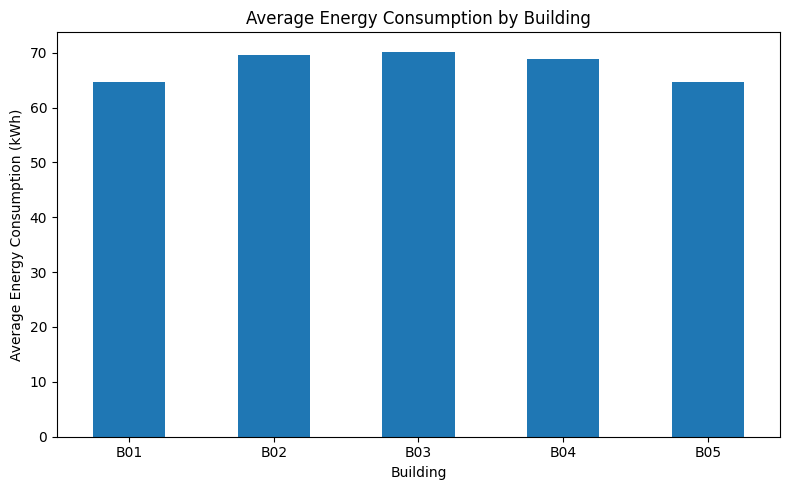

In [10]:
# ============================================================
# PLOT 1: ENERGY CONSUMPTION BY BUILDING
# ============================================================

building_energy = df.groupby(
    "Building_ID"
)["Total_Energy_kWh"].mean()

plt.figure(figsize=(8, 5))

building_energy.plot(
    kind="bar"
)

plt.xlabel("Building")
plt.ylabel("Average Energy Consumption (kWh)")
plt.title("Average Energy Consumption by Building")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

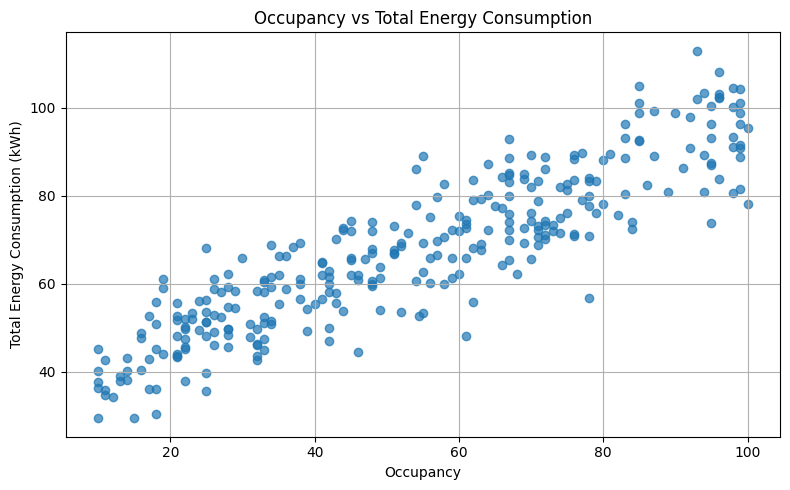

In [11]:
# ============================================================
# PLOT 2: OCCUPANCY VS ENERGY
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Occupancy"],
    df["Total_Energy_kWh"],
    alpha=0.7
)

plt.xlabel("Occupancy")
plt.ylabel("Total Energy Consumption (kWh)")
plt.title("Occupancy vs Total Energy Consumption")
plt.grid(True)
plt.tight_layout()
plt.show()

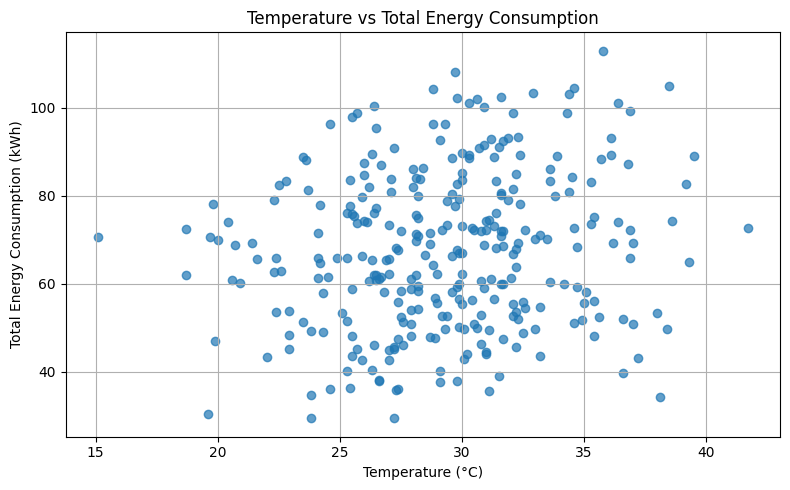

In [12]:
# ============================================================
# PLOT 3: TEMPERATURE VS ENERGY
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Temperature"],
    df["Total_Energy_kWh"],
    alpha=0.7
)

plt.xlabel("Temperature (°C)")
plt.ylabel("Total Energy Consumption (kWh)")
plt.title("Temperature vs Total Energy Consumption")
plt.grid(True)
plt.tight_layout()
plt.show()

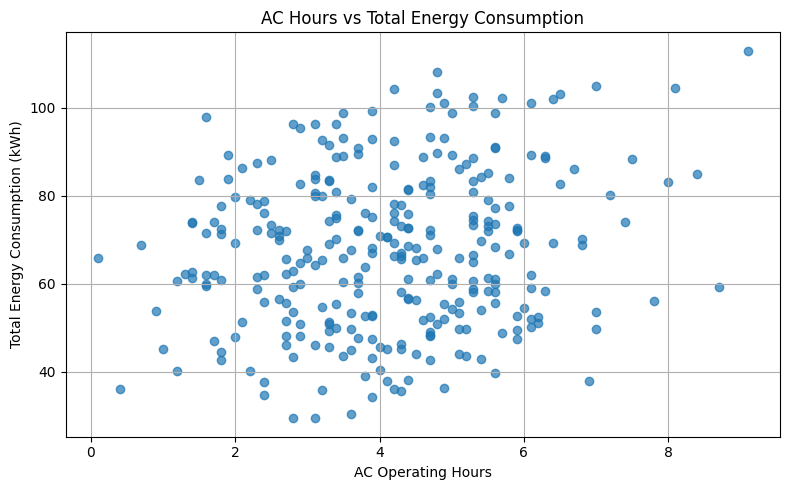

In [13]:
# ============================================================
# PLOT 4: AC HOURS VS ENERGY
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    df["AC_Hours"],
    df["Total_Energy_kWh"],
    alpha=0.7
)

plt.xlabel("AC Operating Hours")
plt.ylabel("Total Energy Consumption (kWh)")
plt.title("AC Hours vs Total Energy Consumption")
plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# CORRELATION ANALYSIS
# ============================================================

numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

print("Correlation with Total_Energy_kWh:")

energy_correlation = (
    correlation["Total_Energy_kWh"]
    .sort_values(ascending=False)
)

display(energy_correlation)

Correlation with Total_Energy_kWh:


,Total_Energy_kWh
Total_Energy_kWh,1.000000
Equipment_Load,0.906241
Occupancy,0.893404
Lighting_Hours,0.814549
AC_Hours,0.176285
Temperature,0.158729
Renewable_Energy_kWh,-0.115931
Humidity,-0.136010


In [15]:
# ============================================================
# MACHINE LEARNING DATA PREPARATION
# ============================================================

features = [
    "Occupancy",
    "Temperature",
    "Humidity",
    "AC_Hours",
    "Lighting_Hours",
    "Equipment_Load",
    "Renewable_Energy_kWh"
]

target = "Total_Energy_kWh"

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Standardization is important for distance-based models
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))
print("Features used   :", len(features))

Training samples: 240
Testing samples : 60
Features used   : 7


In [16]:
# ============================================================
# KNN REGRESSION
# ============================================================

k_values = [3, 5, 7, 9, 11]

knn_results = []

for k in k_values:

    knn = KNeighborsRegressor(
        n_neighbors=k
    )

    knn.fit(
        X_train_scaled,
        y_train
    )

    pred = knn.predict(
        X_test_scaled
    )

    mae = mean_absolute_error(
        y_test, pred
    )

    rmse = np.sqrt(
        mean_squared_error(y_test, pred)
    )

    r2 = r2_score(
        y_test, pred
    )

    knn_results.append(
        [k, mae, rmse, r2]
    )

knn_results = pd.DataFrame(
    knn_results,
    columns=[
        "K",
        "MAE",
        "RMSE",
        "R2"
    ]
)

knn_results = knn_results.sort_values(
    "RMSE"
)

display(knn_results)

,K,MAE,RMSE,R2
4,11,5.348485,6.757041,0.843617
1,5,5.832567,6.970663,0.833572
2,7,5.829214,6.971505,0.833532
3,9,5.725352,7.036330,0.830422
0,3,5.918611,7.305874,0.817181


In [17]:
# ============================================================
# BEST KNN MODEL
# ============================================================

best_k = int(
    knn_results.iloc[0]["K"]
)

best_knn = KNeighborsRegressor(
    n_neighbors=best_k
)

best_knn.fit(
    X_train_scaled,
    y_train
)

knn_prediction = best_knn.predict(
    X_test_scaled
)

knn_mae = mean_absolute_error(
    y_test,
    knn_prediction
)

knn_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        knn_prediction
    )
)

knn_r2 = r2_score(
    y_test,
    knn_prediction
)

print("Best K =", best_k)
print("KNN MAE =", round(knn_mae, 3))
print("KNN RMSE =", round(knn_rmse, 3))
print("KNN R2 =", round(knn_r2, 3))

Best K = 11
KNN MAE = 5.348
KNN RMSE = 6.757
KNN R2 = 0.844


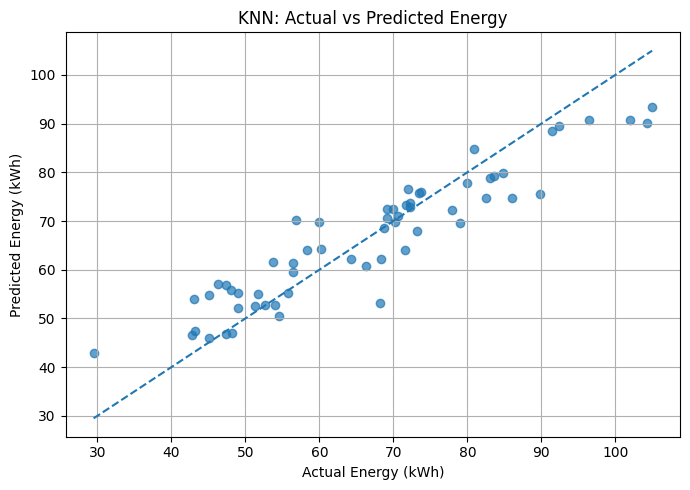

In [18]:
# ============================================================
# ACTUAL VS PREDICTED - KNN
# ============================================================

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    knn_prediction,
    alpha=0.7
)

minimum = min(
    y_test.min(),
    knn_prediction.min()
)

maximum = max(
    y_test.max(),
    knn_prediction.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Energy (kWh)")
plt.ylabel("Predicted Energy (kWh)")
plt.title("KNN: Actual vs Predicted Energy")
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
# ============================================================
# LOCALLY WEIGHTED REGRESSION
# ============================================================

def locally_weighted_predict(
    X_train,
    y_train,
    X_query,
    bandwidth=1.0
):

    predictions = []

    X_train_bias = np.c_[
        np.ones(len(X_train)),
        X_train
    ]

    for x in X_query:

        distances = np.linalg.norm(
            X_train - x,
            axis=1
        )

        weights = np.exp(
            -(distances ** 2) /
            (2 * bandwidth ** 2)
        )

        W = np.diag(weights)

        try:

            theta = np.linalg.pinv(
                X_train_bias.T @ W @ X_train_bias
            ) @ (
                X_train_bias.T @ W @ y_train
            )

            x_bias = np.insert(x, 0, 1)

            prediction = x_bias @ theta

        except:

            prediction = np.average(
                y_train,
                weights=weights
            )

        predictions.append(prediction)

    return np.array(predictions)


# Test different bandwidth values
bandwidths = [0.3, 0.5, 1.0, 1.5, 2.0]

lwr_results = []

for bandwidth in bandwidths:

    lwr_prediction = locally_weighted_predict(
        X_train_scaled,
        y_train.values,
        X_test_scaled,
        bandwidth
    )

    mae = mean_absolute_error(
        y_test,
        lwr_prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            lwr_prediction
        )
    )

    r2 = r2_score(
        y_test,
        lwr_prediction
    )

    lwr_results.append(
        [bandwidth, mae, rmse, r2]
    )

lwr_results = pd.DataFrame(
    lwr_results,
    columns=[
        "Bandwidth",
        "MAE",
        "RMSE",
        "R2"
    ]
)

display(lwr_results)

,Bandwidth,MAE,RMSE,R2
0,0.3,9.779868,14.021922,0.326570
1,0.5,6.898498,9.441992,0.694645
2,1.0,4.483573,5.600724,0.892560
3,1.5,4.382526,5.515284,0.895813
4,2.0,4.359231,5.519586,0.895651


In [20]:
# ============================================================
# BEST LWR MODEL
# ============================================================

best_bandwidth = lwr_results.sort_values(
    "RMSE"
).iloc[0]["Bandwidth"]

best_lwr_prediction = locally_weighted_predict(
    X_train_scaled,
    y_train.values,
    X_test_scaled,
    best_bandwidth
)

lwr_mae = mean_absolute_error(
    y_test,
    best_lwr_prediction
)

lwr_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        best_lwr_prediction
    )
)

lwr_r2 = r2_score(
    y_test,
    best_lwr_prediction
)

print(
    "Best LWR bandwidth:",
    best_bandwidth
)

print(
    "LWR MAE:",
    round(lwr_mae, 3)
)

print(
    "LWR RMSE:",
    round(lwr_rmse, 3)
)

print(
    "LWR R2:",
    round(lwr_r2, 3)
)

Best LWR bandwidth: 1.5
LWR MAE: 4.383
LWR RMSE: 5.515
LWR R2: 0.896


In [21]:
# ============================================================
# RADIAL BASIS FUNCTION REGRESSION
# ============================================================

gamma_values = [0.01, 0.05, 0.1, 0.5, 1.0]

rbf_results = []

for gamma in gamma_values:

    rbf = KernelRidge(
        kernel="rbf",
        gamma=gamma,
        alpha=0.1
    )

    rbf.fit(
        X_train_scaled,
        y_train
    )

    rbf_prediction = rbf.predict(
        X_test_scaled
    )

    mae = mean_absolute_error(
        y_test,
        rbf_prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            rbf_prediction
        )
    )

    r2 = r2_score(
        y_test,
        rbf_prediction
    )

    rbf_results.append(
        [gamma, mae, rmse, r2]
    )

rbf_results = pd.DataFrame(
    rbf_results,
    columns=[
        "Gamma",
        "MAE",
        "RMSE",
        "R2"
    ]
)

display(rbf_results)

,Gamma,MAE,RMSE,R2
0,0.01,4.573150,5.809036,0.884419
1,0.05,4.878068,6.179899,0.869190
2,0.10,5.439147,7.005648,0.831898
3,0.50,16.114858,21.931707,-0.647487
4,1.00,31.488321,38.548904,-4.089807


In [22]:
# ============================================================
# BEST RBF MODEL
# ============================================================

best_gamma = rbf_results.sort_values(
    "RMSE"
).iloc[0]["Gamma"]

best_rbf = KernelRidge(
    kernel="rbf",
    gamma=best_gamma,
    alpha=0.1
)

best_rbf.fit(
    X_train_scaled,
    y_train
)

rbf_prediction = best_rbf.predict(
    X_test_scaled
)

rbf_mae = mean_absolute_error(
    y_test,
    rbf_prediction
)

rbf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rbf_prediction
    )
)

rbf_r2 = r2_score(
    y_test,
    rbf_prediction
)

print("Best RBF gamma:", best_gamma)
print("RBF MAE:", round(rbf_mae, 3))
print("RBF RMSE:", round(rbf_rmse, 3))
print("RBF R2:", round(rbf_r2, 3))

Best RBF gamma: 0.01
RBF MAE: 4.573
RBF RMSE: 5.809
RBF R2: 0.884


In [23]:
# ============================================================
# CASE-BASED LEARNING
# ============================================================

def retrieve_similar_cases(
    query,
    X_train,
    y_train,
    original_train,
    n_cases=5
):

    distances = np.linalg.norm(
        X_train - query,
        axis=1
    )

    nearest_indices = np.argsort(
        distances
    )[:n_cases]

    cases = original_train.iloc[
        nearest_indices
    ].copy()

    cases["Distance"] = distances[
        nearest_indices
    ]

    cases["Energy"] = y_train.iloc[
        nearest_indices
    ].values

    return cases


# Select one test condition
query_index = 0

query = X_test_scaled[
    query_index
]

similar_cases = retrieve_similar_cases(
    query,
    X_train_scaled,
    y_train.reset_index(drop=True),
    X_train.reset_index(drop=True),
    n_cases=5
)

print("Five most similar historical cases:")
display(similar_cases)

Five most similar historical cases:


,Occupancy,Temperature,Humidity,AC_Hours,Lighting_Hours,Equipment_Load,Renewable_Energy_kWh,Distance,Energy
7,18.0,32.5,55.1,5.1,4.2,12.0,4.99,1.038373,55.88
193,33.0,33.6,48.9,3.5,5.2,17.5,5.12,1.279461,60.44
157,48.0,32.2,52.8,4.8,3.9,19.8,7.37,1.408187,67.95
170,16.0,28.9,56.0,3.7,1.5,13.9,4.74,1.596795,47.70
135,27.0,35.1,55.0,5.6,3.3,9.7,3.86,1.596843,58.09


In [24]:
# ============================================================
# CASE-BASED PREDICTION
# ============================================================

def case_based_prediction(
    query,
    X_train,
    y_train,
    k=5
):

    distances = np.linalg.norm(
        X_train - query,
        axis=1
    )

    nearest = np.argsort(
        distances
    )[:k]

    # Distance-weighted prediction
    weights = 1 / (
        distances[nearest] + 1e-5
    )

    prediction = np.sum(
        weights * y_train[nearest]
    ) / np.sum(weights)

    return prediction


cbl_predictions = []

for query in X_test_scaled:

    pred = case_based_prediction(
        query,
        X_train_scaled,
        y_train.values,
        k=5
    )

    cbl_predictions.append(pred)

cbl_predictions = np.array(
    cbl_predictions
)

cbl_mae = mean_absolute_error(
    y_test,
    cbl_predictions
)

cbl_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        cbl_predictions
    )
)

cbl_r2 = r2_score(
    y_test,
    cbl_predictions
)

print("Case-Based Learning Results")
print("---------------------------")
print("MAE :", round(cbl_mae, 3))
print("RMSE:", round(cbl_rmse, 3))
print("R2  :", round(cbl_r2, 3))

Case-Based Learning Results
---------------------------
MAE : 5.816
RMSE: 6.909
R2  : 0.836


In [26]:
# ============================================================
# MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame({

    "Model": [
        "KNN",
        "Locally Weighted Regression",
        "RBF Regression",
        "Case-Based Learning"
    ],

    "MAE": [
        knn_mae,
        lwr_mae,
        rbf_mae,
        cbl_mae
    ],

    "RMSE": [
        knn_rmse,
        lwr_rmse,
        rbf_rmse,
        cbl_rmse
    ],

    "R2": [
        knn_r2,
        lwr_r2,
        rbf_r2,
        cbl_r2
    ]
})

comparison = comparison.sort_values(
    "RMSE"
).reset_index(drop=True)

comparison[
    ["MAE", "RMSE", "R2"]
] = comparison[
    ["MAE", "RMSE", "R2"]
].round(3)

display(comparison)

,Model,MAE,RMSE,R2
0,Locally Weighted Regression,4.383,5.515,0.896
1,RBF Regression,4.573,5.809,0.884
2,KNN,5.348,6.757,0.844
3,Case-Based Learning,5.816,6.909,0.836


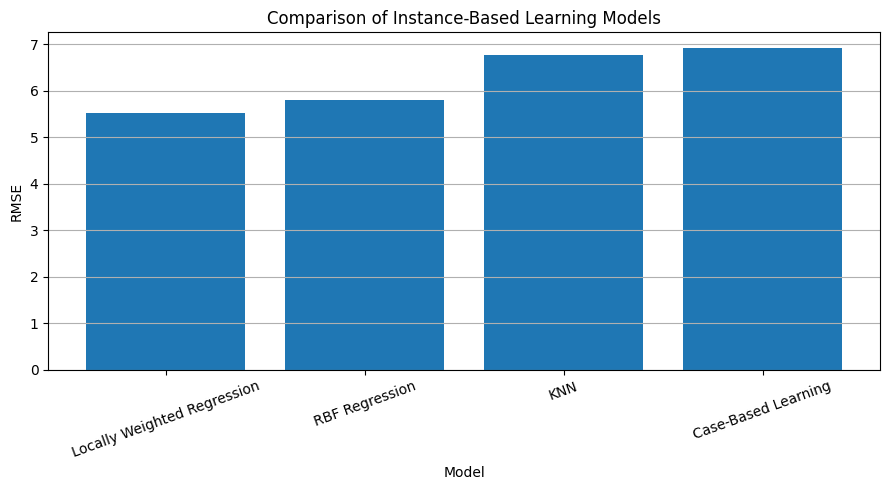

In [27]:
# ============================================================
# MODEL COMPARISON VISUALIZATION
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Model"],
    comparison["RMSE"]
)

plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("Comparison of Instance-Based Learning Models")
plt.xticks(rotation=20)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [28]:
# ============================================================
# BEST MODEL SELECTION
# ============================================================

best_model_name = comparison.iloc[0]["Model"]
best_model_rmse = comparison.iloc[0]["RMSE"]
best_model_mae = comparison.iloc[0]["MAE"]
best_model_r2 = comparison.iloc[0]["R2"]

print("BEST MODEL")
print("==========")
print("Model :", best_model_name)
print("MAE   :", best_model_mae)
print("RMSE  :", best_model_rmse)
print("R2    :", best_model_r2)

BEST MODEL
Model : Locally Weighted Regression
MAE   : 4.383
RMSE  : 5.515
R2    : 0.896


In [29]:
# ============================================================
# NEW CAMPUS CONDITION
# ============================================================

new_condition = pd.DataFrame({

    "Occupancy": [60],

    "Temperature": [30],

    "Humidity": [68],

    "AC_Hours": [8],

    "Lighting_Hours": [8],

    "Equipment_Load": [20],

    "Renewable_Energy_kWh": [4]

})

new_condition_scaled = scaler.transform(
    new_condition[features]
)

# Predictions from all models

new_knn_prediction = best_knn.predict(
    new_condition_scaled
)[0]

new_lwr_prediction = locally_weighted_predict(
    X_train_scaled,
    y_train.values,
    new_condition_scaled,
    best_bandwidth
)[0]

new_rbf_prediction = best_rbf.predict(
    new_condition_scaled
)[0]

new_cbl_prediction = case_based_prediction(
    new_condition_scaled[0],
    X_train_scaled,
    y_train.values,
    k=5
)

new_predictions = pd.DataFrame({

    "Model": [
        "KNN",
        "LWR",
        "RBF",
        "Case-Based Learning"
    ],

    "Predicted_Energy_kWh": [
        new_knn_prediction,
        new_lwr_prediction,
        new_rbf_prediction,
        new_cbl_prediction
    ]
})

new_predictions[
    "Predicted_Energy_kWh"
] = new_predictions[
    "Predicted_Energy_kWh"
].round(2)

display(new_predictions)

,Model,Predicted_Energy_kWh
0,KNN,77.01
1,LWR,82.22
2,RBF,82.45
3,Case-Based Learning,82.83


In [30]:
# ============================================================
# FINAL PREDICTION USING BEST MODEL
# ============================================================

prediction_map = {
    "KNN": new_knn_prediction,
    "Locally Weighted Regression": new_lwr_prediction,
    "RBF Regression": new_rbf_prediction,
    "Case-Based Learning": new_cbl_prediction
}

final_prediction = prediction_map[
    best_model_name
]

print(
    "Predicted Total Energy Consumption:",
    round(final_prediction, 2),
    "kWh"
)

Predicted Total Energy Consumption: 82.22 kWh


In [31]:
# ============================================================
# ENERGY EFFICIENCY RECOMMENDATION
# ============================================================

recommendations = []

if final_prediction > 85:

    recommendations.append(
        "HIGH ENERGY CONSUMPTION: Reduce unnecessary AC operation."
    )

    recommendations.append(
        "Switch off lighting in unoccupied areas."
    )

    recommendations.append(
        "Reduce unnecessary laboratory/equipment operation."
    )

elif final_prediction > 65:

    recommendations.append(
        "MODERATE ENERGY CONSUMPTION: Optimize AC operating hours."
    )

    recommendations.append(
        "Use lighting only in occupied areas."
    )

    recommendations.append(
        "Monitor equipment standby consumption."
    )

else:

    recommendations.append(
        "ENERGY CONSUMPTION IS WITHIN THE ACCEPTABLE RANGE."
    )

    recommendations.append(
        "Continue monitoring occupancy and equipment usage."
    )

# Additional recommendations
if new_condition["Occupancy"].iloc[0] < 30:
    recommendations.append(
        "Low occupancy detected: reduce lighting and AC operation."
    )

if new_condition["AC_Hours"].iloc[0] > 8:
    recommendations.append(
        "AC usage is high: optimize cooling schedule."
    )

if new_condition["Renewable_Energy_kWh"].iloc[0] < 3:
    recommendations.append(
        "Consider increasing renewable-energy utilization."
    )

print("ENERGY EFFICIENCY RECOMMENDATIONS")
print("=================================")

for i, recommendation in enumerate(
    recommendations,
    start=1
):
    print(f"{i}. {recommendation}")

ENERGY EFFICIENCY RECOMMENDATIONS
1. MODERATE ENERGY CONSUMPTION: Optimize AC operating hours.
2. Use lighting only in occupied areas.
3. Monitor equipment standby consumption.


In [32]:
# ============================================================
# FINAL REPORT
# ============================================================

print("=" * 60)
print("SMART CAMPUS ENERGY ANALYTICS REPORT")
print("=" * 60)

print("\nInput Condition:")
display(new_condition)

print(
    "\nBest Prediction Model:",
    best_model_name
)

print(
    "Predicted Energy:",
    round(final_prediction, 2),
    "kWh"
)

print(
    "\nModel Performance:"
)

display(comparison)

print(
    "\nEnergy Efficiency Recommendations:"
)

for i, recommendation in enumerate(
    recommendations,
    start=1
):

    print(
        f"{i}. {recommendation}"
    )

SMART CAMPUS ENERGY ANALYTICS REPORT

Input Condition:


,Occupancy,Temperature,Humidity,AC_Hours,Lighting_Hours,Equipment_Load,Renewable_Energy_kWh
0,60,30,68,8,8,20,4



Best Prediction Model: Locally Weighted Regression
Predicted Energy: 82.22 kWh

Model Performance:


,Model,MAE,RMSE,R2
0,Locally Weighted Regression,4.383,5.515,0.896
1,RBF Regression,4.573,5.809,0.884
2,KNN,5.348,6.757,0.844
3,Case-Based Learning,5.816,6.909,0.836



Energy Efficiency Recommendations:
1. MODERATE ENERGY CONSUMPTION: Optimize AC operating hours.
2. Use lighting only in occupied areas.
3. Monitor equipment standby consumption.


In [33]:
# ============================================================
# SAVE RESULTS
# ============================================================

comparison.to_csv(
    "model_comparison_results.csv",
    index=False
)

new_predictions.to_csv(
    "new_condition_predictions.csv",
    index=False
)

building_summary.to_csv(
    "building_energy_summary.csv"
)

print("All result files saved successfully.")

print("\nGenerated files:")
print("1. cleaned_campus_energy.csv")
print("2. model_comparison_results.csv")
print("3. new_condition_predictions.csv")
print("4. building_energy_summary.csv")

All result files saved successfully.

Generated files:
1. cleaned_campus_energy.csv
2. model_comparison_results.csv
3. new_condition_predictions.csv
4. building_energy_summary.csv


In [34]:
# ============================================================
# REFLECTION AND LIMITATIONS
# ============================================================

print("=" * 60)
print("REFLECTION AND LIMITATIONS")
print("=" * 60)

print("""
1. KNN was selected because energy consumption under similar
   operating conditions can be predicted from historical cases.

2. Feature standardization was necessary because KNN, LWR,
   RBF and Case-Based Learning depend on distance/similarity.

3. Multiple K values were tested to study the effect of the
   neighbourhood size on prediction accuracy.

4. LWR was included because local observations may have
   different relationships compared with the complete dataset.

5. RBF was included to model nonlinear similarity between
   campus operating conditions.

6. Case-Based Learning provides an interpretable prediction
   because the system can retrieve similar historical cases.

7. MAE and RMSE were used because lower values indicate
   smaller prediction errors, while R2 measures explained
   variation in energy consumption.

8. The system provides practical recommendations instead of
   only reporting a predicted energy value.

9. The dataset used in this prototype is synthetic. Therefore,
   real campus data should be used before actual deployment.

10. Important future improvements include real-time IoT sensor
    integration, weather APIs, occupancy sensors, electricity
    meter data and a web-based dashboard.
""")

REFLECTION AND LIMITATIONS

1. KNN was selected because energy consumption under similar
   operating conditions can be predicted from historical cases.

2. Feature standardization was necessary because KNN, LWR,
   RBF and Case-Based Learning depend on distance/similarity.

3. Multiple K values were tested to study the effect of the
   neighbourhood size on prediction accuracy.

4. LWR was included because local observations may have
   different relationships compared with the complete dataset.

5. RBF was included to model nonlinear similarity between
   campus operating conditions.

6. Case-Based Learning provides an interpretable prediction
   because the system can retrieve similar historical cases.

7. MAE and RMSE were used because lower values indicate
   smaller prediction errors, while R2 measures explained
   variation in energy consumption.

8. The system provides practical recommendations instead of
   only reporting a predicted energy value.

9. The dataset used in this 

In [35]:
# ============================================================
# SDG MAPPING
# ============================================================

sdg_mapping = pd.DataFrame({

    "SDG": [
        "SDG 7",
        "SDG 11",
        "SDG 12",
        "SDG 13"
    ],

    "Goal": [
        "Affordable and Clean Energy",
        "Sustainable Cities and Communities",
        "Responsible Consumption and Production",
        "Climate Action"
    ],

    "Project Contribution": [
        "Predicts and reduces unnecessary electricity consumption.",
        "Supports sustainable and intelligent campus operation.",
        "Promotes efficient use of electrical resources.",
        "Helps reduce energy wastage and associated emissions."
    ]
})

display(sdg_mapping)

,SDG,Goal,Project Contribution
0,SDG 7,Affordable and Clean Energy,Predicts and reduces unnecessary electricity c...
1,SDG 11,Sustainable Cities and Communities,Supports sustainable and intelligent campus op...
2,SDG 12,Responsible Consumption and Production,Promotes efficient use of electrical resources.
3,SDG 13,Climate Action,Helps reduce energy wastage and associated emi...


In [36]:
# ============================================================
# FINAL DEMONSTRATION SUMMARY
# ============================================================

print("\n" + "="*65)
print("SMART CAMPUS ENERGY CONSUMPTION PREDICTION SYSTEM")
print("="*65)

print("\nDataset:")
print("Records used:", len(df))
print("Features:", len(features))
print("Target:", target)

print("\nBest Model:")
print(best_model_name)

print("\nPerformance:")
print("MAE :", best_model_mae)
print("RMSE:", best_model_rmse)
print("R2  :", best_model_r2)

print("\nNew Campus Condition:")
print("Occupancy:", new_condition["Occupancy"].iloc[0])
print("Temperature:", new_condition["Temperature"].iloc[0], "°C")
print("AC Hours:", new_condition["AC_Hours"].iloc[0])
print("Equipment Load:",
      new_condition["Equipment_Load"].iloc[0])

print(
    "\nPredicted Energy:",
    round(final_prediction, 2),
    "kWh"
)

print("\nRecommendation:")

for recommendation in recommendations:
    print("-", recommendation)

print("\nSDG Mapping: SDG 7, SDG 11, SDG 12, SDG 13")

print("\nSystem execution completed successfully.")


SMART CAMPUS ENERGY CONSUMPTION PREDICTION SYSTEM

Dataset:
Records used: 300
Features: 7
Target: Total_Energy_kWh

Best Model:
Locally Weighted Regression

Performance:
MAE : 4.383
RMSE: 5.515
R2  : 0.896

New Campus Condition:
Occupancy: 60
Temperature: 30 °C
AC Hours: 8
Equipment Load: 20

Predicted Energy: 82.22 kWh

Recommendation:
- MODERATE ENERGY CONSUMPTION: Optimize AC operating hours.
- Use lighting only in occupied areas.
- Monitor equipment standby consumption.

SDG Mapping: SDG 7, SDG 11, SDG 12, SDG 13

System execution completed successfully.
